In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# 1. Membaca dan menampilkan dataset
dataset = pd.read_csv("transaction.csv")
display(dataset)

,InvoiceNo,StockCode,Qty,InvoiceDate,CustomerID,Country
0,537626,22725,830,12/7/2010 14:57,12347,Iceland
1,537626,22729,948,12/7/2010 14:57,12347,Iceland
2,537626,22195,695,12/7/2010 14:57,12347,Iceland
3,542237,22725,636,1/26/2011 14:30,12347,Iceland
4,542237,22729,536,1/26/2011 14:30,12347,Iceland
...,...,...,...,...,...,...
10541,543911,21700,455,2/14/2011 12:46,17829,United Arab Emirates
10542,543911,22111,578,2/14/2011 12:46,17829,United Arab Emirates
10543,543911,22112,163,2/14/2011 12:46,17829,United Arab Emirates
10544,564428,23296,545,8/25/2011 11:27,17844,Canada


In [2]:
# 2. Menghitung kemunculan setiap negara
country = dataset["Country"].value_counts()

print("Jumlah kemunculan setiap negara:")
display(country)

Jumlah kemunculan setiap negara:


Country
Germany                 2269
France                  2109
EIRE                    1620
Netherlands              634
Spain                    539
Belgium                  486
Switzerland              434
Portugal                 367
Australia                356
Norway                   239
Italy                    190
Channel Islands          184
Finland                  152
Cyprus                   113
Sweden                   109
Denmark                   98
Japan                     92
Austria                   88
Poland                    80
Israel                    61
USA                       47
Singapore                 45
Unspecified               44
Canada                    36
Iceland                   35
Greece                    33
United Arab Emirates      23
Malta                     15
RSA                       14
Brazil                     8
Lithuania                  8
Lebanon                    5
European Community         5
Czech Republic             4
Bahrai

In [3]:
# 3. Menghitung rata-rata Qty per transaksi setiap negara

# Menghapus data yang tidak memiliki InvoiceNo atau Country
data_valid = dataset.dropna(
    subset=["InvoiceNo", "Country", "Qty"]
).copy()

# Menghitung total Qty untuk setiap transaksi
qty_per_transaksi = (
    data_valid
    .groupby(["Country", "InvoiceNo"])["Qty"]
    .sum()
    .reset_index()
)

# Menghitung rata-rata Qty per transaksi setiap negara
transaksi = (
    qty_per_transaksi
    .groupby("Country")["Qty"]
    .mean()
    .reset_index()
)

transaksi.columns = [
    "Country",
    "Rata_Rata_Qty"
]

print("Rata-rata Qty per transaksi setiap negara:")
display(transaksi)

Rata-rata Qty per transaksi setiap negara:


,Country,Rata_Rata_Qty
0,Australia,4026.295455
1,Austria,3420.250000
2,Bahrain,1470.000000
3,Belgium,3032.714286
4,Brazil,4389.000000
5,Canada,6449.666667
6,Channel Islands,4569.714286
7,Cyprus,3550.875000
8,Czech Republic,1239.500000
9,Denmark,3018.888889


In [4]:
# 4. K-Means clustering sebanyak 10 kali
X = transaksi[["Rata_Rata_Qty"]].values

cluster_i = []
cluster_val = []

for i in range(10):
    kmeans = KMeans(
        n_clusters=3,
        n_init=1,
        random_state=i
    )

    labels = kmeans.fit_predict(X)

    # Menghitung SSE
    sse = kmeans.inertia_

    # Menyimpan hasil clustering
    cluster_i.append({
        "labels": labels,
        "centroids": kmeans.cluster_centers_.flatten()
    })

    # Menyimpan nilai SSE
    cluster_val.append(sse)

    print(f"Percobaan {i+1}: SSE = {sse:.4f}")

Percobaan 1: SSE = 13229107.1985
Percobaan 2: SSE = 16420994.7082
Percobaan 3: SSE = 13229107.1985
Percobaan 4: SSE = 16420994.7082
Percobaan 5: SSE = 13229107.1985
Percobaan 6: SSE = 13229107.1985
Percobaan 7: SSE = 13229107.1985
Percobaan 8: SSE = 13229107.1985
Percobaan 9: SSE = 13229107.1985
Percobaan 10: SSE = 16420994.7082


In [5]:
# 5. Memilih hasil clustering terbaik
indeks_terbaik = np.argmin(cluster_val)

cluster = cluster_i[indeks_terbaik]

print("Percobaan terbaik:", indeks_terbaik + 1)
print("SSE terkecil:", cluster_val[indeks_terbaik])

Percobaan terbaik: 3
SSE terkecil: 13229107.19852232


In [6]:
# 6. Mengambil posisi centroid
centroid = cluster["centroids"]

print("Posisi centroid:")
for i, nilai in enumerate(centroid):
    print(f"Cluster {i}: {nilai:.4f}")

Posisi centroid:
Cluster 0: 3542.2195
Cluster 1: 6173.8508
Cluster 2: 1400.1303


In [7]:
# 7. Mengurutkan posisi centroid dari terkecil ke terbesar
sorted_idx = np.argsort(centroid)

sorted_centroid = centroid[sorted_idx]

print("Centroid setelah diurutkan:")
for i, nilai in enumerate(sorted_centroid):
    print(f"Urutan {i+1}: {nilai:.4f}")

Centroid setelah diurutkan:
Urutan 1: 1400.1303
Urutan 2: 3542.2195
Urutan 3: 6173.8508


In [8]:
# 8. Menentukan kategori setiap negara

label_rendah = sorted_idx[0]
label_sedang = sorted_idx[1]
label_tinggi = sorted_idx[2]

# Mengambil label cluster dari hasil terbaik
hasil_cluster = transaksi.copy()
hasil_cluster["Cluster"] = cluster["labels"]

# Menentukan kategori berdasarkan urutan centroid
kategori = {
    label_rendah: "Rendah",
    label_sedang: "Sedang",
    label_tinggi: "Tinggi"
}

hasil_cluster["Kategori"] = (
    hasil_cluster["Cluster"].map(kategori)
)

# Menampilkan negara berdasarkan kategori
for tingkat in ["Rendah", "Sedang", "Tinggi"]:
    negara = hasil_cluster.loc[
        hasil_cluster["Kategori"] == tingkat,
        "Country"
    ]

    print(f"\nNegara dengan transaksi {tingkat}:")
    print(negara.to_list())

print("\nTabel hasil clustering:")
display(hasil_cluster)


Negara dengan transaksi Rendah:
['Bahrain', 'Czech Republic', 'European Community', 'Lithuania', 'Saudi Arabia', 'Sweden']

Negara dengan transaksi Sedang:
['Australia', 'Austria', 'Belgium', 'Brazil', 'Channel Islands', 'Cyprus', 'Denmark', 'EIRE', 'Finland', 'France', 'Germany', 'Greece', 'Iceland', 'Italy', 'Japan', 'Lebanon', 'Malta', 'Netherlands', 'Norway', 'Poland', 'Portugal', 'Spain', 'Unspecified']

Negara dengan transaksi Tinggi:
['Canada', 'Israel', 'RSA', 'Singapore', 'Switzerland', 'USA', 'United Arab Emirates']

Tabel hasil clustering:


,Country,Rata_Rata_Qty,Cluster,Kategori
0,Australia,4026.295455,0,Sedang
1,Austria,3420.250000,0,Sedang
2,Bahrain,1470.000000,2,Rendah
3,Belgium,3032.714286,0,Sedang
4,Brazil,4389.000000,0,Sedang
5,Canada,6449.666667,1,Tinggi
6,Channel Islands,4569.714286,0,Sedang
7,Cyprus,3550.875000,0,Sedang
8,Czech Republic,1239.500000,2,Rendah
9,Denmark,3018.888889,0,Sedang


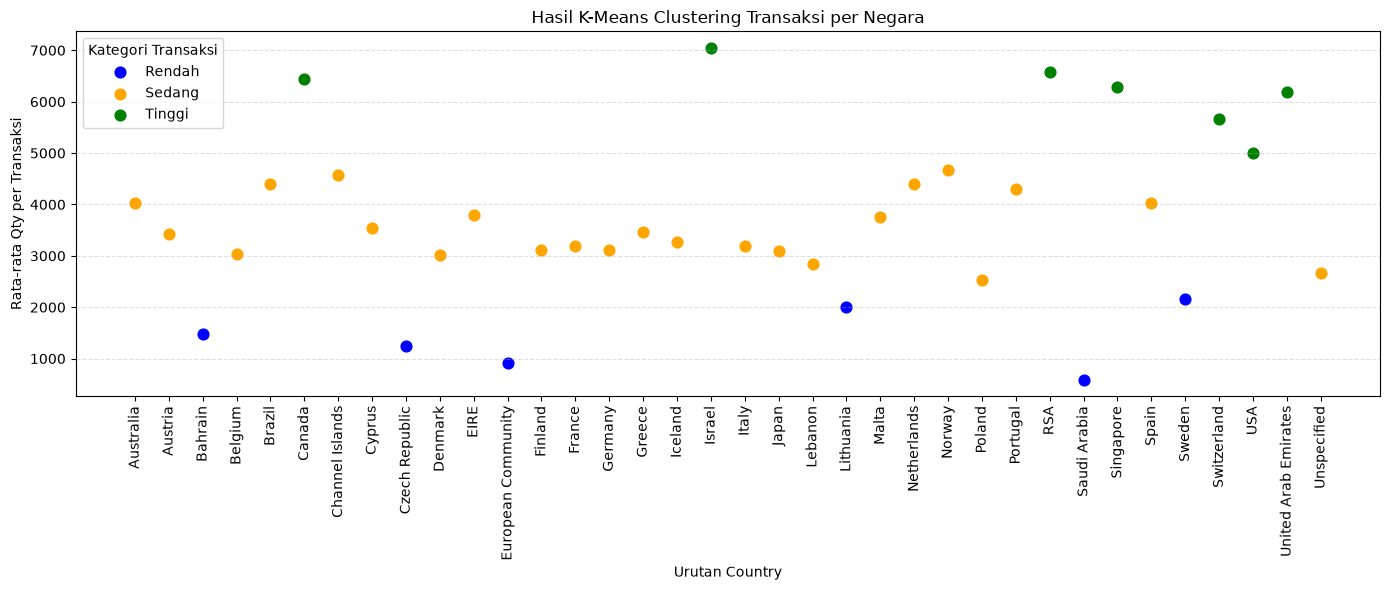

In [9]:
# 9. Visualisasi hasil clustering

# Mengurutkan negara berdasarkan nama
plot_data = hasil_cluster.sort_values(
    "Country"
).reset_index(drop=True)

# Menentukan urutan negara pada sumbu X
plot_data["Urutan"] = range(1, len(plot_data) + 1)

# Warna untuk setiap kategori
warna = {
    "Rendah": "blue",
    "Sedang": "orange",
    "Tinggi": "green"
}

plt.figure(figsize=(14, 6))

for tingkat in ["Rendah", "Sedang", "Tinggi"]:
    data_kategori = plot_data[
        plot_data["Kategori"] == tingkat
    ]

    plt.scatter(
        data_kategori["Urutan"],
        data_kategori["Rata_Rata_Qty"],
        color=warna[tingkat],
        label=tingkat,
        s=60
    )

# Label sumbu X menggunakan nama negara
plt.xticks(
    plot_data["Urutan"],
    plot_data["Country"],
    rotation=90
)

plt.xlabel("Urutan Country")
plt.ylabel("Rata-rata Qty per Transaksi")
plt.title("Hasil K-Means Clustering Transaksi per Negara")

plt.legend(title="Kategori Transaksi")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()